## Learning $y  \leftarrow x_1 \land x_2$ for boolean inputs

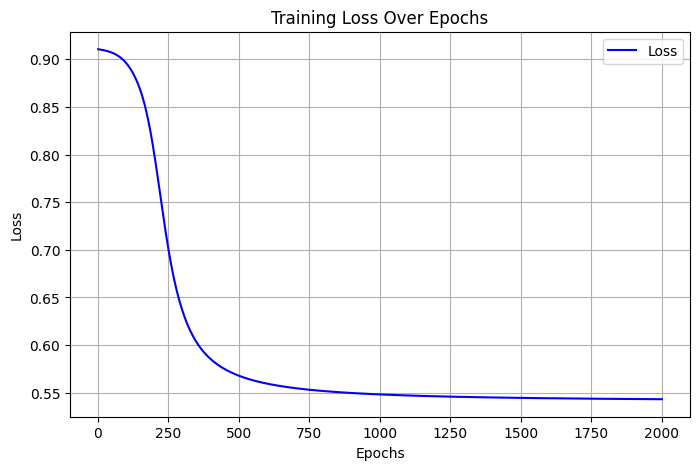

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(10*torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  # No tensor wrapping

        # Apply log function
        return torch.log(stable_input)

# Full Network with Two Neurons (Different Inputs)
class CustomNeuralNet(nn.Module):
    def __init__(self):
        super(CustomNeuralNet, self).__init__()
        self.neuron1 = CustomNeuron()
        self.neuron2 = CustomNeuron()
    
    def forward(self, x):
        # Split input into two separate inputs (each neuron gets a different feature)
        x1 = x[:, [0]]  # Feature for neuron 1
        x2 = x[:, [1]]  # Feature for neuron 2
        
        # Compute neuron outputs
        out1 = self.neuron1(x1)
        out2 = self.neuron2(x2)
        
        # Sum outputs and apply exponentiation
        output = torch.exp(out1 + out2)
        
        return output

# Generate Synthetic Data (Binary Classification with Two Inputs)
torch.manual_seed(42)
num_samples = 10

X_train = (torch.rand(num_samples, 2) > 0.5).float()  # 100 samples, 2 input features
y_train = (X_train[:, 0] * X_train[:, 1]).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet()
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 2000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()


In [2]:
print(f'Weights1: {torch.sigmoid(model.neuron1.raw_weights)}.')
print(f'Weights2: {torch.sigmoid(model.neuron2.raw_weights)}.\n')

Weights1: tensor([9.9801e-01, 1.8878e-05, 9.9937e-05], grad_fn=<SigmoidBackward0>).
Weights2: tensor([9.9897e-01, 2.6009e-04, 3.6919e-03], grad_fn=<SigmoidBackward0>).



## Learning $y  \leftarrow x_1 \land x_2$ for probabilistic inputs

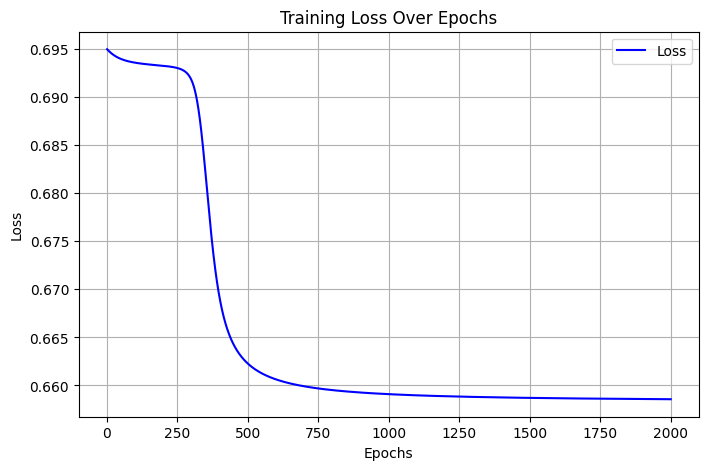

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(-10*torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  # No tensor wrapping

        # Apply log function
        return torch.log(stable_input)

# Full Network with Two Neurons (Different Inputs)
class CustomNeuralNet(nn.Module):
    def __init__(self):
        super(CustomNeuralNet, self).__init__()
        self.neuron1 = CustomNeuron()
        self.neuron2 = CustomNeuron()
    
    def forward(self, x):
        # Split input into two separate inputs (each neuron gets a different feature)
        x1 = x[:, [0]]  # Feature for neuron 1
        x2 = x[:, [1]]  # Feature for neuron 2
        
        # Compute neuron outputs
        out1 = self.neuron1(x1)
        out2 = self.neuron2(x2)
        
        # Sum outputs and apply exponentiation
        output = torch.exp(out1 + out2)
        
        return output

# Generate Synthetic Data (Binary Classification with Two Inputs)
torch.manual_seed(42)
num_samples = 100

X_train = torch.rand(num_samples, 2)  # 100 samples, 2 input features
y_train = (X_train[:, 0] * X_train[:, 1] > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet()
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 2000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()


In [3]:
# Test Prediction
with torch.no_grad():
    X_test = torch.tensor([[0.0, 0.0], [0.2, 0.3], [0.7, 0.8], [0.5, 0.5], [0.9, 0.1], [1.0, 1.0]])
    predictions = [model(X_test) > 0.25]  # Convert logits to probabilities
    print("\nTest Predictions:")
    print(predictions)


Test Predictions:
[tensor([[False],
        [False],
        [ True],
        [False],
        [False],
        [ True]])]


In [4]:
print(f'Weights1: {torch.sigmoid(model.neuron1.raw_weights)}.')
print(f'Weights2: {torch.sigmoid(model.neuron2.raw_weights)}.\n')

Weights1: tensor([9.9709e-01, 1.5219e-04, 4.2874e-07], grad_fn=<SigmoidBackward0>).
Weights2: tensor([9.9614e-01, 2.7710e-05, 2.1112e-04], grad_fn=<SigmoidBackward0>).



In [7]:
X_train[1,:]

tensor([0.3829, 0.9593])

In [6]:
y_train[1]

tensor(1.)

## Adding Mislabeled data to the outputs

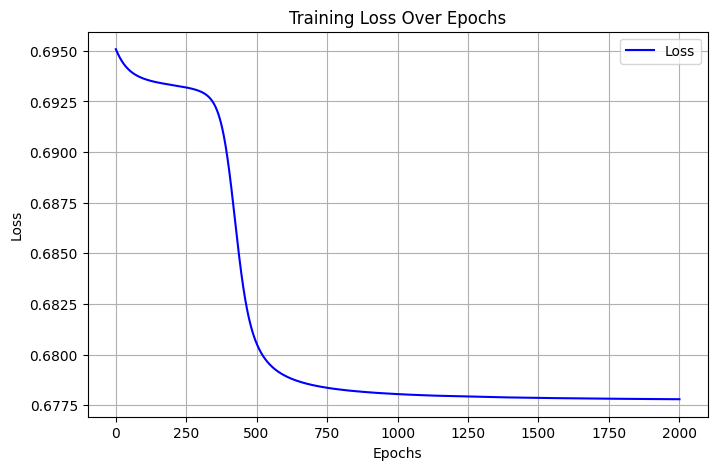

In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(-10*torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  # No tensor wrapping

        # Apply log function
        return torch.log(stable_input)

# Full Network with Two Neurons (Different Inputs)
class CustomNeuralNet(nn.Module):
    def __init__(self):
        super(CustomNeuralNet, self).__init__()
        self.neuron1 = CustomNeuron()
        self.neuron2 = CustomNeuron()
    
    def forward(self, x):
        # Split input into two separate inputs (each neuron gets a different feature)
        x1 = x[:, [0]]  # Feature for neuron 1
        x2 = x[:, [1]]  # Feature for neuron 2
        
        # Compute neuron outputs
        out1 = self.neuron1(x1)
        out2 = self.neuron2(x2)
        
        # Sum outputs and apply exponentiation
        output = torch.exp(out1 + out2)
        
        return output

# Generate Synthetic Data (Binary Classification with Two Inputs)
torch.manual_seed(42)
num_samples = 100

X_train = torch.rand(num_samples, 2)  # 100 samples, 2 input features
y_train = (X_train[:, 0] * X_train[:, 1] > 0.25).float()  # Threshold for classification

num_mislabeled = int(0.05 * num_samples)
mislabeled_indices = torch.randperm(num_samples)[:num_mislabeled]
y_train[mislabeled_indices] = 1 - y_train[mislabeled_indices]

# Model, Loss, Optimizer
model = CustomNeuralNet()
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 2000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()


In [12]:
# Test Prediction
with torch.no_grad():
    X_test = torch.tensor([[0.0, 0.0], [0.2, 0.3], [0.7, 0.8], [0.5, 0.5], [0.9, 0.1], [1.0, 1.0]])
    predictions = [model(X_test) > 0.25]  # Convert logits to probabilities
    print("\nTest Predictions:")
    print(predictions)


Test Predictions:
[tensor([[False],
        [False],
        [ True],
        [False],
        [False],
        [ True]])]


In [13]:
print(f'Weights1: {torch.sigmoid(model.neuron1.raw_weights)}.')
print(f'Weights2: {torch.sigmoid(model.neuron2.raw_weights)}.\n')

Weights1: tensor([9.8705e-01, 5.8901e-05, 2.1742e-04], grad_fn=<SigmoidBackward0>).
Weights2: tensor([9.9918e-01, 5.0453e-05, 1.9499e-04], grad_fn=<SigmoidBackward0>).



## Learning $y  \leftarrow x_1 \land \bar{x}_2$

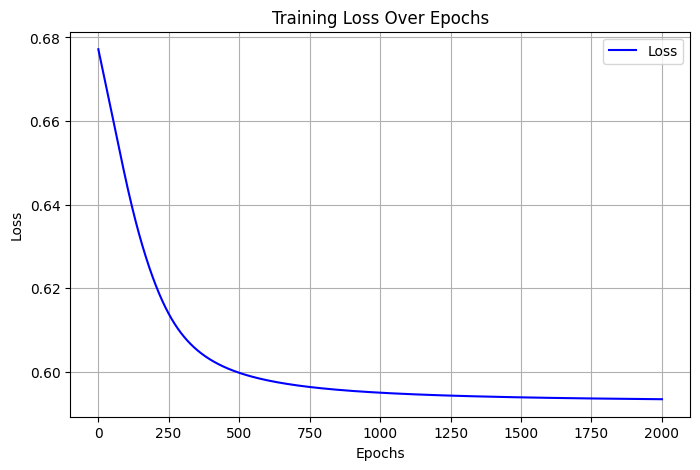

In [17]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(-1*torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  # No tensor wrapping

        # Apply log function
        return torch.log(stable_input)

# Full Network with Two Neurons (Different Inputs)
class CustomNeuralNet(nn.Module):
    def __init__(self):
        super(CustomNeuralNet, self).__init__()
        self.neuron1 = CustomNeuron()
        self.neuron2 = CustomNeuron()
    
    def forward(self, x):
        # Split input into two separate inputs (each neuron gets a different feature)
        x1 = x[:, [0]]  # Feature for neuron 1
        x2 = x[:, [1]]  # Feature for neuron 2
        
        # Compute neuron outputs
        out1 = self.neuron1(x1)
        out2 = self.neuron2(x2)
        
        # Sum outputs and apply exponentiation
        output = torch.exp(out1 + out2)
        
        return output

# Generate Synthetic Data (Binary Classification with Two Inputs)
torch.manual_seed(42)
num_samples = 100

X_train = torch.rand(num_samples, 2)  # 100 samples, 2 input features
y_train = (X_train[:, 0] * (1 - X_train[:, 1]) > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet()
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 2000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()


In [18]:
# Test Prediction
with torch.no_grad():
    X_test = torch.tensor([[0.2, 0.3], [0.7, 0.8], [0.5, 0.5], [0.9, 0.1]])
    predictions = [model(X_test) > 0.25]  # Convert logits to probabilities
    print("\nTest Predictions:")
    print(predictions)


Test Predictions:
[tensor([[False],
        [False],
        [ True],
        [ True]])]


In [19]:
print(f'Weights1: {torch.sigmoid(model.neuron1.raw_weights)}.')
print(f'Weights2: {torch.sigmoid(model.neuron2.raw_weights)}.')

Weights1: tensor([0.9974, 0.0043, 0.0017], grad_fn=<SigmoidBackward0>).
Weights2: tensor([0.0028, 0.9978, 0.0015], grad_fn=<SigmoidBackward0>).


## Learning $y  \leftarrow x_1 \land x_2$ with a redundant input

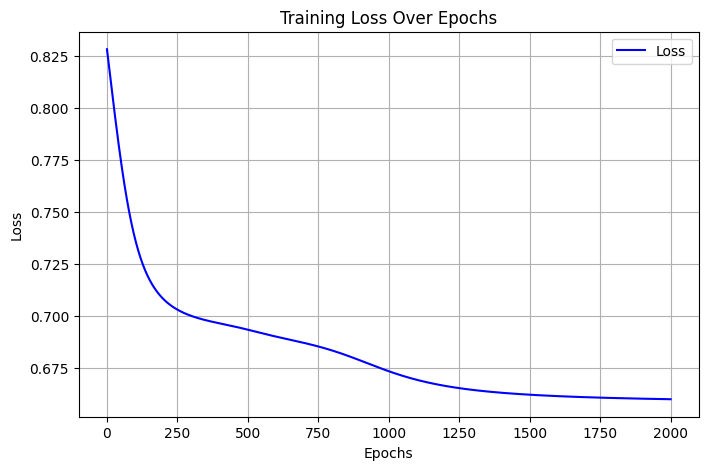

In [20]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Full Network with Three Neurons (Different Inputs)
class CustomNeuralNet(nn.Module):
    def __init__(self):
        super(CustomNeuralNet, self).__init__()
        self.neuron1 = CustomNeuron()
        self.neuron2 = CustomNeuron()
        self.neuron3 = CustomNeuron()  # Added third neuron
    
    def forward(self, x):
        # Split input into three separate inputs (each neuron gets a different feature)
        x1 = x[:, [0]]  # Feature for neuron 1
        x2 = x[:, [1]]  # Feature for neuron 2
        x3 = x[:, [2]]  # Feature for neuron 3 (a combination of x1 and x2)

        # Compute neuron outputs
        out1 = self.neuron1(x1)
        out2 = self.neuron2(x2)
        out3 = self.neuron3(x3)

        # Sum outputs and apply exponentiation
        output = torch.exp(out1 + out2 + out3)
        
        return output

# Generate Synthetic Data (Binary Classification with Two Inputs)
torch.manual_seed(42)
num_samples = 100

X_train = torch.rand(num_samples, 3)  # 100 samples, 2 input features
y_train = (X_train[:, 0] * X_train[:, 1] > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet()
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 2000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()


In [21]:
# Test Prediction
with torch.no_grad():
    X_test = torch.tensor([[0.2, 0.3, 0.0], [0.7, 0.8, 0.0], [0.5, 0.5, 1.0], [0.9, 0.1, 0.0]])
    predictions = [model(X_test) > 0.25]  # Convert logits to probabilities
    print("\nTest Predictions:")
    print(predictions)


Test Predictions:
[tensor([[False],
        [ True],
        [ True],
        [False]])]


In [22]:
print(f'Weights1: {torch.sigmoid(model.neuron1.raw_weights)}.')
print(f'Weights2: {torch.sigmoid(model.neuron2.raw_weights)}.')
print(f'Weights3: {torch.sigmoid(model.neuron3.raw_weights)}.\n')

Weights1: tensor([0.9981, 0.0045, 0.0055], grad_fn=<SigmoidBackward0>).
Weights2: tensor([0.9979, 0.0033, 0.0066], grad_fn=<SigmoidBackward0>).
Weights3: tensor([0.8773, 0.7383, 0.9341], grad_fn=<SigmoidBackward0>).



## Learning $y  \leftarrow x_1 \land x_2$ with two redundant inputs

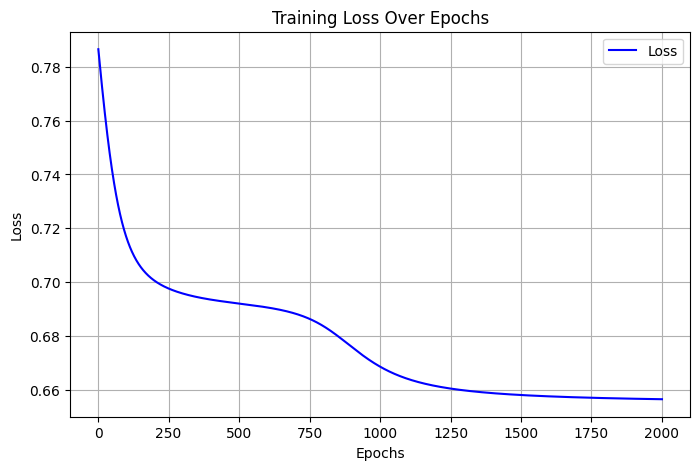

In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Full Network with Three Neurons (Different Inputs)
class CustomNeuralNet(nn.Module):
    def __init__(self):
        super(CustomNeuralNet, self).__init__()
        self.neuron1 = CustomNeuron()
        self.neuron2 = CustomNeuron()
        self.neuron3 = CustomNeuron() 
        self.neuron4 = CustomNeuron()  # Added third neuron
    
    def forward(self, x):
        # Split input into three separate inputs (each neuron gets a different feature)
        x1 = x[:, [0]]  # Feature for neuron 1
        x2 = x[:, [1]]  # Feature for neuron 2
        x3 = x[:, [2]]  # Feature for neuron 3 (a combination of x1 and x2)
        x4 = x[:, [3]]

        # Compute neuron outputs
        out1 = self.neuron1(x1)
        out2 = self.neuron2(x2)
        out3 = self.neuron3(x3)
        out4 = self.neuron4(x4)

        # Sum outputs and apply exponentiation
        output = torch.exp(out1 + out2 + out3 + out4)
        
        return output

# Generate Synthetic Data (Binary Classification with Two Inputs)
torch.manual_seed(42)
num_samples = 100

X_train = torch.rand(num_samples, 4)  # 100 samples, 2 input features
y_train = (X_train[:, 0] * X_train[:, 1] > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet()
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 2000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()


In [6]:
# Test Prediction
with torch.no_grad():
    X_test = torch.tensor([[0.2, 0.3, 0.0, 0.0], [0.7, 0.8, 0.0, 1.0], [0.5, 0.5, 1.0, 0.0], [0.9, 0.1, 0.0, 1.0]])
    predictions = [model(X_test) > 0.25]  # Convert logits to probabilities
    print("\nTest Predictions:")
    print(predictions)


Test Predictions:
[tensor([[False],
        [ True],
        [False],
        [False]])]


In [7]:
print(f'Weights1: {torch.sigmoid(model.neuron1.raw_weights)}.')
print(f'Weights2: {torch.sigmoid(model.neuron2.raw_weights)}.')
print(f'Weights3: {torch.sigmoid(model.neuron3.raw_weights)}.')
print(f'Weights4: {torch.sigmoid(model.neuron4.raw_weights)}.\n')

Weights1: tensor([0.9996, 0.0024, 0.0027], grad_fn=<SigmoidBackward0>).
Weights2: tensor([0.9990, 0.0033, 0.0036], grad_fn=<SigmoidBackward0>).
Weights3: tensor([0.7423, 0.9140, 0.9646], grad_fn=<SigmoidBackward0>).
Weights4: tensor([0.8481, 0.8969, 0.9654], grad_fn=<SigmoidBackward0>).



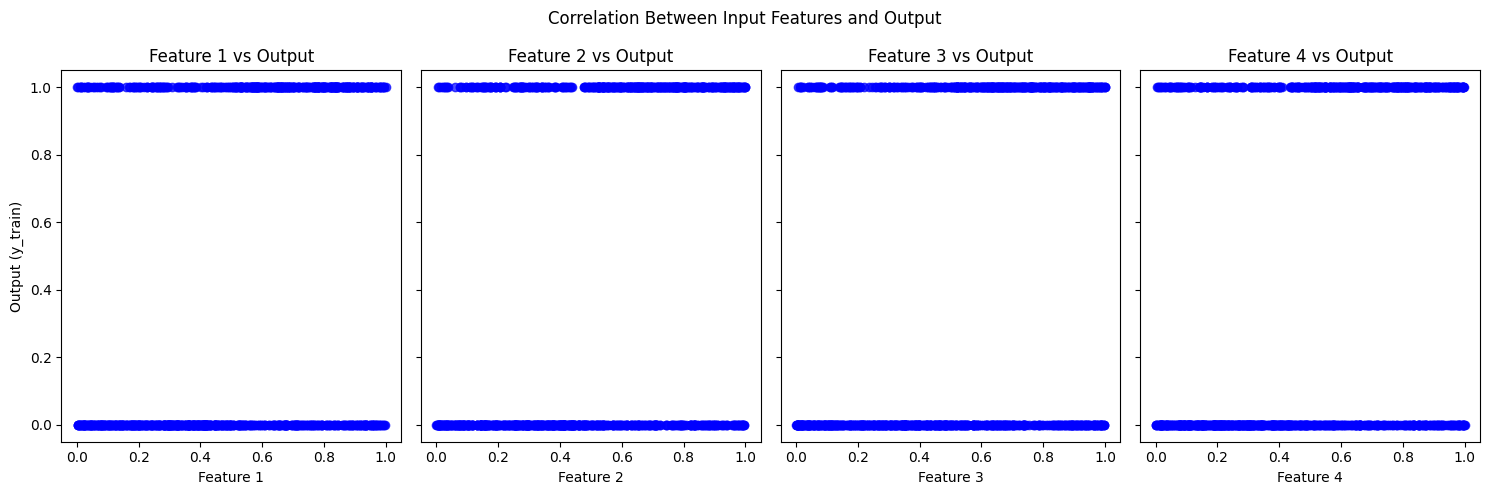

In [6]:
import matplotlib.pyplot as plt

# Plot correlation between each input feature and the output
num_features = X_train.shape[1]  # Number of input features
fig, axes = plt.subplots(1, num_features, figsize=(15, 5), sharey=True)

for i in range(num_features):
    axes[i].scatter(X_train[:, i].detach().numpy(), y_train.detach().numpy(), alpha=0.7, color='blue')
    axes[i].set_xlabel(f"Feature {i+1}")
    axes[i].set_title(f"Feature {i+1} vs Output")

axes[0].set_ylabel("Output (y_train)")
plt.suptitle("Correlation Between Input Features and Output")
plt.tight_layout()
plt.show()

## Process Automation

Adding more inputs


Final Weights of the Network:
Neuron 1 Weights: [9.9999666e-01 9.2879054e-06 4.9903751e-06]
Neuron 2 Weights: [0.9904578 0.984294  0.9999776]
Neuron 3 Weights: [0.991991  0.9777866 0.9999671]
Neuron 4 Weights: [0.9840312 0.9834599 0.999967 ]
Neuron 5 Weights: [1.0194263e-05 9.9999738e-01 8.2171255e-06]
Neuron 6 Weights: [0.98744375 0.9785745  0.9999758 ]
Neuron 7 Weights: [0.98041624 0.99206287 0.999979  ]
Neuron 8 Weights: [0.9874414 0.9843796 0.9999757]
Neuron 9 Weights: [0.9819519  0.9893468  0.99998033]
Neuron 10 Weights: [0.9858628 0.975685  0.9999739]


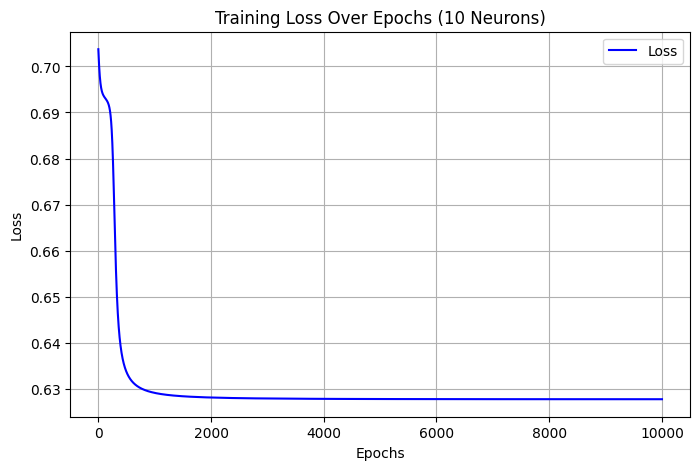

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output

# User-Specified Number of Neurons
num_neurons = 10  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(41)
num_samples = 200
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * (1-X_train[:, 4]) > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 10000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

Weights = []
# Print Final Weights After Training
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    Weights.append(weights)
    print(f"Neuron {i+1} Weights: {weights}")

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()


In [2]:
import numpy as np

def interpret_neuron_weights(weights):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    interpretations = []
    for i, neuron_weights in enumerate(weights):
        max_index = np.argmax(neuron_weights)
        if all(neuron_weights) == 1.0 or (neuron_weights[2] == 1 and neuron_weights[1] == 1) or (neuron_weights[2] == 1 and neuron_weights[0] == 1):
            interpretations.append('1')
            continue
        elif max_index == 0:
            interpretations.append(f'b{i+1}')
            continue
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
            continue
        else:
            interpretations.append('1')
    return interpretations

In [35]:
neuron_weights = [[1.0, 1.0, 1.0],[1.0, 0.0, 1.0],[0.0, 1.0, 0.0]]
all(neuron_weights) == 1

interpret_neuron_weights(neuron_weights)

['1', '1', 'not(b3)']

In [18]:
preds = interpret_neuron_weights(Weights)
refined_preds = [pred for pred in preds if pred != '1']
final_rule = f"h :- " + " and ".join(refined_preds) + "."
print("\nFinal Rule:")
print(final_rule)
    


Final Rule:
h :- b_1 and not(b_5).


In [2]:
# Test Prediction
with torch.no_grad():
    X_test = torch.tensor([[0.2, 0.3, 0.0, 0.0], [0.7, 0.8, 0.0, 1.0], [0.5, 0.5, 1.0, 0.0], [0.9, 0.1, 0.0, 1.0]])
    predictions = [model(X_test) > 0.25]  # Convert logits to probabilities
    print("\nTest Predictions:")
    print(predictions)


Test Predictions:
[tensor([[False],
        [ True],
        [False],
        [False]])]


In [42]:
# Print Final Weights After Training
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    print(f"Neuron {i+1} Weights: {weights}")


Final Weights of the Network:
Neuron 1 Weights: [9.9999845e-01 5.4042021e-06 6.1680689e-06]
Neuron 2 Weights: [0.9512181 0.9875761 0.9999676]
Neuron 3 Weights: [0.97841716 0.9813565  0.99996746]
Neuron 4 Weights: [0.9813223  0.9740897  0.99995613]
Neuron 5 Weights: [5.1326178e-06 9.9999869e-01 7.2384673e-06]
Neuron 6 Weights: [0.9802649 0.9838271 0.999964 ]
Neuron 7 Weights: [0.9801875  0.9817816  0.99996245]
Neuron 8 Weights: [0.980485  0.9771955 0.9999715]
Neuron 9 Weights: [0.97496116 0.9855679  0.999977  ]
Neuron 10 Weights: [0.9935137  0.96557873 0.9999684 ]


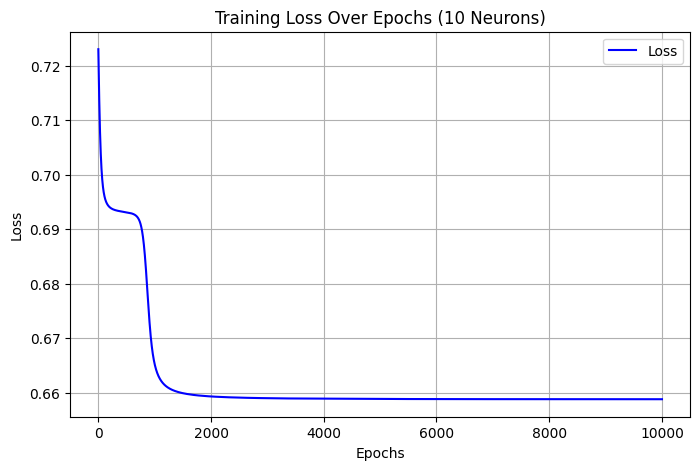


Final Weights of the Network:
Neuron 1 Weights: [1. 0. 0.]
Neuron 2 Weights: [1. 1. 1.]
Neuron 3 Weights: [1. 1. 1.]
Neuron 4 Weights: [1. 1. 1.]
Neuron 5 Weights: [0. 1. 0.]
Neuron 6 Weights: [1. 1. 1.]
Neuron 7 Weights: [1. 1. 1.]
Neuron 8 Weights: [1. 1. 1.]
Neuron 9 Weights: [1. 1. 1.]
Neuron 10 Weights: [0. 1. 0.]

Final Rule:
h :- b1 and not(b5) and not(b10).



In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import random

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output

# User-Specified Number of Neurons
num_neurons = 10  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(41)
num_samples = 200
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * (1-X_train[:, 4]) *  (1 - X_train[:, 9])  > 0.125).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 10000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Print Final Weights After Training
Weights = []
Rounded_weights = []
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    # Round the weights to the nearest number (e.g., nearest integer)
    rounded_weights = np.round(weights, decimals=0)  # Adjust `decimals` as needed (e.g., 0 for integers)
    
    Weights.append(weights)
    Rounded_weights.append(rounded_weights)
    print(f"Neuron {i+1} Weights: {rounded_weights}")

preds = interpret_neuron_weights(Rounded_weights)
refined_preds = [pred for pred in preds if pred != '1']
final_rule = f"h :- " + " and ".join(refined_preds) + "."
print("\n==========================================")
print("Final Rule:")
print(final_rule)
print("==========================================\n")


## Learning two rules

The code cannot extract two rules using one layer network. We should add the second layer to define different combinations of rules.

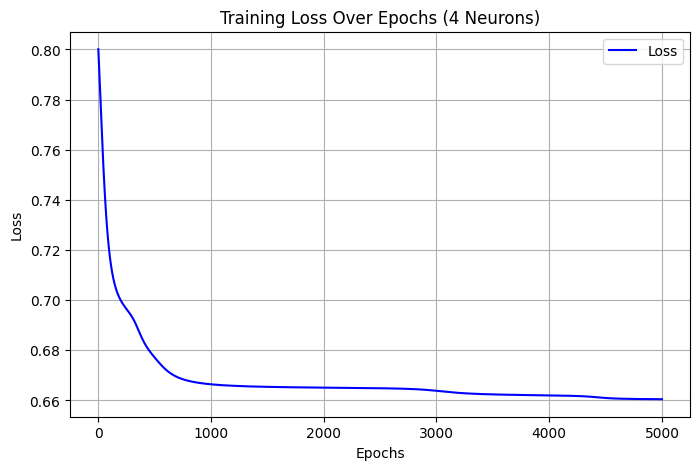


Final Weights of the Network:
Neuron 1 Weights: [1. 0. 0.]
Neuron 2 Weights: [1. 0. 1.]
Neuron 3 Weights: [1. 0. 0.]
Neuron 4 Weights: [1. 0. 0.]
Neuron 1 Weights: [1. 0. 0.]
Neuron 2 Weights: [1. 0. 0.]
Neuron 3 Weights: [1. 0. 0.]
Neuron 4 Weights: [1. 0. 1.]

h1 :- b1 and b3 and b4.

h2 :- b1 and b2 and b3.



In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons1 = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.neurons2 = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs1, outputs2 = [], []
        for i, neuron in enumerate(self.neurons1):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs1.append(neuron(xi))

        for i, neuron in enumerate(self.neurons2):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs2.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output1 = torch.exp(sum(outputs1))
        output2 = torch.exp(sum(outputs2))
        return output1 + output2 - output1*output2
        # return torch.max(output1, output2)  # Use max to combine outputs

# User-Specified Number of Neurons
num_neurons = 4  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(41)
num_samples = 1000
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()  # Logical operations

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 5000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()

    # Compute BCE loss
    loss = criterion(outputs, y_train)
    
    # Compute KL divergence between neurons1 and neurons2
    kl_divergence = 0
    for neuron1, neuron2 in zip(model.neurons1, model.neurons2):
        weights1 = torch.sigmoid(neuron1.raw_weights)
        weights2 = torch.sigmoid(neuron2.raw_weights)
        kl_divergence += torch.sum(weights1 * torch.log(weights1 / (weights2 + 1e-6) + 1e-6))

    sparsity_loss = 0
    for neuron in model.neurons1 + model.neurons2:
        weights = torch.sigmoid(neuron.raw_weights)  # Normalize weights
        softmax_weights = torch.softmax(weights, dim=0)  # Apply softmax
        entropy = -torch.sum(softmax_weights * torch.log(softmax_weights + 1e-6))  # Compute entropy
        sparsity_loss += entropy  # Accumulate entropy for all neurons
        
    # Subtract KL divergence from the loss
    total_loss = loss #+ 0.0001 * sparsity_loss #- 0.01* torch.sqrt(kl_divergence)
    
    # Backpropagation
    total_loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(total_loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Print Final Weights After Training
Weights1 = []
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons1):
    weights1 = torch.sigmoid(neuron.raw_weights).detach().numpy()
    weights1 = np.round(weights1, decimals=0)  # Adjust `decimals` as needed (e.g., 0 for integers)
    Weights1.append(weights1)
    print(f"Neuron {i+1} Weights: {weights1}")

Weights2 = []
for i, neuron in enumerate(model.neurons2):
    weights2 = torch.sigmoid(neuron.raw_weights).detach().numpy()
    weights2 = np.round(weights2, decimals=0)  # Adjust `decimals` as needed (e.g., 0 for integers)
    Weights2.append(weights2)
    print(f"Neuron {i+1} Weights: {weights2}")

preds1 = interpret_neuron_weights(Weights1)
refined_preds1 = [pred for pred in preds1 if pred != '1']
print("==========================================\n")
print(f"h1 :- " + " and ".join(refined_preds1) + ".")
preds2 = interpret_neuron_weights(Weights2)
refined_preds2 = [pred for pred in preds2 if pred != '1']
print("==========================================\n")
print(f"h2 :- " + " and ".join(refined_preds2) + ".")
print("==========================================\n")


## Using K-Means Clustering to split data into a couple of single-rule subdatasets

In [36]:
from sklearn.cluster import KMeans
import numpy as np

X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()  # Logical operations

# Apply K-Means clustering to split the data into two clusters
kmeans = KMeans(n_clusters=2, random_state=42)
cluster_labels = kmeans.fit_predict(X_train.detach().numpy())

# Split the dataset based on cluster labels
X_train_rule1 = X_train[cluster_labels == 0]
y_train_rule1 = y_train[cluster_labels == 0]

X_train_rule2 = X_train[cluster_labels == 1]
y_train_rule2 = y_train[cluster_labels == 1]

print(f"Rule 1 Dataset Size: {len(X_train_rule1)}")
print(f"Rule 2 Dataset Size: {len(X_train_rule2)}")

Rule 1 Dataset Size: 94
Rule 2 Dataset Size: 106


## Using Decision Tree to split data

In [39]:
from sklearn.tree import DecisionTreeClassifier

X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()  # Logical operations

# Train a decision tree classifier
tree = DecisionTreeClassifier(max_depth=1, random_state=42)  # Limit depth to 1 for a single split
tree.fit(X_train.detach().numpy(), y_train.detach().numpy())

# Get the split condition
split_feature = tree.tree_.feature[0]
split_threshold = tree.tree_.threshold[0]

# Split the dataset based on the decision tree's first split
X_train_rule1 = X_train[X_train[:, split_feature] <= split_threshold]
y_train_rule1 = y_train[X_train[:, split_feature] <= split_threshold]

X_train_rule2 = X_train[X_train[:, split_feature] > split_threshold]
y_train_rule2 = y_train[X_train[:, split_feature] > split_threshold]

print(f"Rule 1 Dataset Size: {len(X_train_rule1)}")
print(f"Rule 2 Dataset Size: {len(X_train_rule2)}")

Rule 1 Dataset Size: 102
Rule 2 Dataset Size: 98


## Feature Importance Modeling

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance

X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()  # Logical operations

# Train a logistic regression model
model = LogisticRegression()
model.fit(X_train.detach().numpy(), y_train.detach().numpy())

# Get feature importance
importance = np.abs(model.coef_[0])
most_important_feature = np.argmax(importance)

# Split the dataset based on the most important feature
threshold = X_train[:, most_important_feature].mean()  # Example threshold
X_train_rule1 = X_train[X_train[:, most_important_feature] <= threshold]
y_train_rule1 = y_train[X_train[:, most_important_feature] <= threshold]

X_train_rule2 = X_train[X_train[:, most_important_feature] > threshold]
y_train_rule2 = y_train[X_train[:, most_important_feature] > threshold]

print(f"Rule 1 Dataset Size: {len(X_train_rule1)}")
print(f"Rule 2 Dataset Size: {len(X_train_rule2)}")

Rule 1 Dataset Size: 97
Rule 2 Dataset Size: 103


## Feature Contribution Analysis

In [4]:
import torch

input_dim = 4  # Number of input features

num_samples = 100
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()  # Logical operations

# Compute pairwise products
pair1 = X_train[:, 0] * X_train[:, 1]  # a * b
pair2 = X_train[:, 2] * X_train[:, 3]  # c * d

# Compute correlation with the output
correlation_pair1 = torch.corrcoef(torch.stack([pair1, y_train]))[0, 1]
correlation_pair2 = torch.corrcoef(torch.stack([pair2, y_train]))[0, 1]

print(f"Correlation with pair1 (a * b): {correlation_pair1}")
print(f"Correlation with pair2 (c * d): {correlation_pair2}")

# Assign outputs to feature pairs
group1_mask = torch.abs(pair1 - y_train) < torch.abs(pair2 - y_train)
group2_mask = ~group1_mask  # Complement of group1_mask

# Split the dataset
X_train_group1 = X_train[group1_mask]
y_train_group1 = y_train[group1_mask]

X_train_group2 = X_train[group2_mask]
y_train_group2 = y_train[group2_mask]

Correlation with pair1 (a * b): 0.5363088250160217
Correlation with pair2 (c * d): 0.5761545896530151


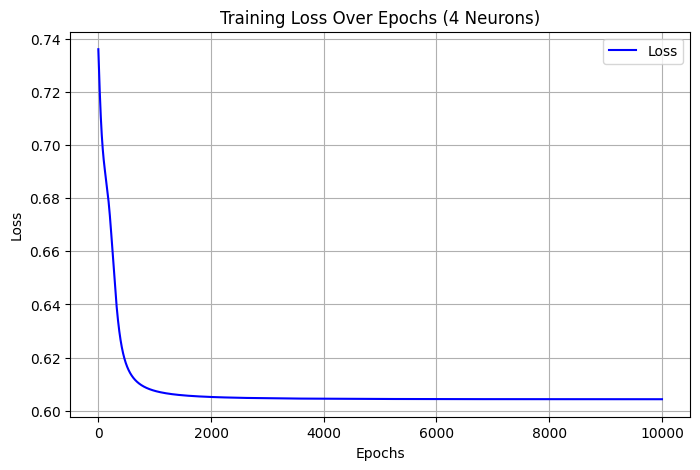


Final Weights of the Network:
Neuron 1 Weights: [0.9747069  0.97847086 0.9999213 ]
Neuron 1 Rounded Weights: [1. 1. 1.]
Neuron 2 Weights: [0.9847761 0.9702486 0.9999012]
Neuron 2 Rounded Weights: [1. 1. 1.]
Neuron 3 Weights: [9.9999058e-01 2.1601087e-05 2.3886123e-05]
Neuron 3 Rounded Weights: [1. 0. 0.]
Neuron 4 Weights: [9.9999416e-01 2.2746832e-05 3.0705942e-05]
Neuron 4 Rounded Weights: [1. 0. 0.]

Final Rule:
h :- b3 and b4.



In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import random

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output

# User-Specified Number of Neurons
num_neurons = 4  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(41)
num_samples = 200
X_train = X_train_group2  # Auto-adjusted input dimension
y_train = y_train_group2  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 10000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Print Final Weights After Training
Weights = []
Rounded_weights = []
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    # Round the weights to the nearest number (e.g., nearest integer)
    rounded_weights = np.round(weights, decimals=0)  # Adjust `decimals` as needed (e.g., 0 for integers)
    
    Weights.append(weights)
    Rounded_weights.append(rounded_weights)
    print(f"Neuron {i+1} Weights: {weights}")
    print(f"Neuron {i+1} Rounded Weights: {rounded_weights}")

preds = interpret_neuron_weights(Rounded_weights)
refined_preds = [pred for pred in preds if pred != '1']
final_rule = f"h :- " + " and ".join(refined_preds) + "."
print("\n==========================================")
print("Final Rule:")
print(final_rule)
print("==========================================\n")


In [44]:
torch.sum(y_train_rule2 == 0.0).item()

32

In [42]:
# Concatenate X_train and y_train
dataset = torch.cat([X_train, y_train.unsqueeze(1)], dim=1)  # Add y_train as the last column

# Convert to a NumPy array for better readability (optional)
dataset_np = dataset.numpy()

# Print the dataset as a table
import pandas as pd
columns = [f"X_{i+1}" for i in range(X_train.shape[1])] + ["y"]
df = pd.DataFrame(dataset_np, columns=columns)
print(df)

          X_1       X_2       X_3       X_4    y
0    0.212983  0.905460  0.745468  0.849979  1.0
1    0.141600  0.967326  0.318437  0.223602  0.0
2    0.332864  0.532309  0.791879  0.372126  0.0
3    0.162305  0.580889  0.018616  0.101729  0.0
4    0.607555  0.945041  0.211034  0.783414  1.0
..        ...       ...       ...       ...  ...
495  0.312300  0.738119  0.299022  0.882227  0.0
496  0.145251  0.414121  0.924464  0.290164  0.0
497  0.508965  0.353088  0.676476  0.247723  0.0
498  0.122197  0.311810  0.701652  0.370347  0.0
499  0.116563  0.395662  0.281826  0.915678  0.0

[500 rows x 5 columns]


In [43]:
# Count the number of 1.0 in the 'y' column
num_ones = (df['y'] == 1.0).sum()
print(f"Number of 1.0 in y: {num_ones}")

Number of 1.0 in y: 206


## How to add constraints to the network?

# Appendix

## Normalization Techniques (did not work)


Final Weights of the Network:
Neuron 1 Weights: [0.7219166  0.22277929 0.21102084], Sum: 1.1557
Neuron 2 Weights: [0.6964418  0.12118161 0.10230675], Sum: 0.9199
Neuron 3 Weights: [0.2367234  0.37895483 0.1748372 ], Sum: 0.7905
Neuron 4 Weights: [0.49794722 0.38162884 0.24305673], Sum: 1.1226


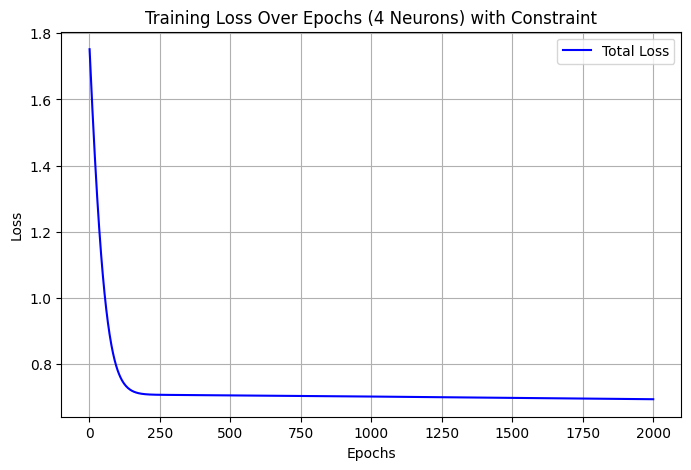

In [5]:
# Re-import necessary libraries after execution state reset
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input), weights.sum()  # Return both output and weight sum

# Fully Automated Neural Network with Constraint
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        total_weight_sum = 0  # To accumulate weight sum across neurons
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            out, weight_sum = neuron(xi)  # Get both the neuron output and weight sum
            outputs.append(out)
            total_weight_sum += weight_sum

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output, total_weight_sum

# User-Specified Number of Neurons
num_neurons = 4  # Set number of neurons
input_dim = 4  # Adjust as needed

# Generate Synthetic Data
torch.manual_seed(42)
num_samples = 100
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * X_train[:, 1] > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop with Constraint
num_epochs = 2000
losses = []
lambda_reg = 0.1  # Regularization strength for the constraint

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs, total_weight_sum = model(X_train)
    outputs = outputs.squeeze()
    
    # Compute primary loss
    loss = criterion(outputs, y_train)
    
    # Compute weight constraint loss
    constraint_loss = lambda_reg * (total_weight_sum - num_neurons) ** 2  # (sum(weights) - num_neurons)^2
    
    # Combined loss
    total_loss = loss + constraint_loss

    # Backpropagation
    total_loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(total_loss.item())

# Print Final Weights After Training
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    print(f"Neuron {i+1} Weights: {weights}, Sum: {weights.sum():.4f}")

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Total Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons) with Constraint")
plt.legend()
plt.grid(True)
plt.show()



Final Weights of the Network:
Neuron 1 Weights: [0.32997084 0.35701716 0.31196594], Sum: 0.9990
Neuron 2 Weights: [0.4338659  0.30960646 0.25546244], Sum: 0.9989
Neuron 3 Weights: [0.31008956 0.3742087  0.31465062], Sum: 0.9989
Neuron 4 Weights: [0.3890295  0.3213277  0.28858784], Sum: 0.9989
Neuron 5 Weights: [0.38813692 0.29248634 0.31831717], Sum: 0.9989
Neuron 6 Weights: [0.34579784 0.29492566 0.35822597], Sum: 0.9989
Neuron 7 Weights: [0.32062608 0.33341494 0.34491128], Sum: 0.9990
Neuron 8 Weights: [0.3306189  0.2881844  0.38014156], Sum: 0.9989
Neuron 9 Weights: [0.42316687 0.30064487 0.2751344 ], Sum: 0.9989
Neuron 10 Weights: [0.32219338 0.31213874 0.364641  ], Sum: 0.9990


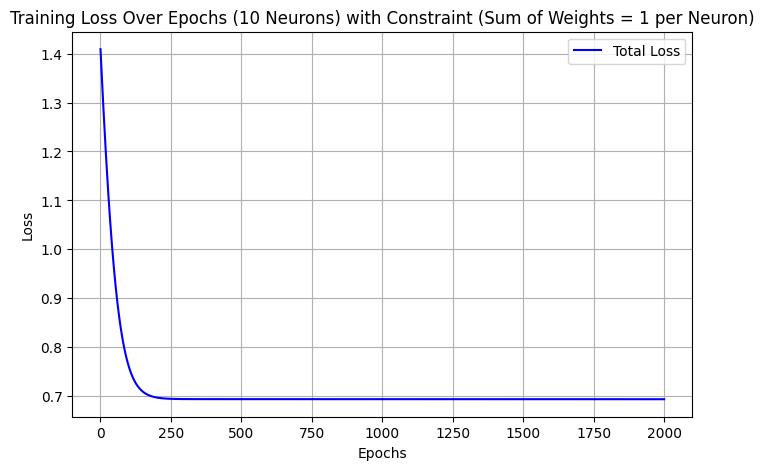

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input), weights.sum()  # Return both output and weight sum

# Fully Automated Neural Network with Constraint
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        weight_sums = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            out, weight_sum = neuron(xi)  # Get both the neuron output and weight sum
            outputs.append(out)
            weight_sums.append(weight_sum)

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output, weight_sums

# User-Specified Number of Neurons
num_neurons = 10  # Set number of neurons
input_dim = 4  # Adjust as needed

# Generate Synthetic Data
torch.manual_seed(42)
num_samples = 100
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * X_train[:, 1] > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop with Constraint
num_epochs = 2000
losses = []
lambda_reg = 0.1  # Regularization strength for the constraint

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs, weight_sums = model(X_train)
    outputs = outputs.squeeze()
    
    # Compute primary loss
    loss = criterion(outputs, y_train)
    
    # Compute weight constraint loss
    constraint_loss = lambda_reg * sum((weight_sum - 1) ** 2 for weight_sum in weight_sums)  # (sum(weights) - 1)^2 for each neuron
    
    # Combined loss
    total_loss = loss + constraint_loss

    # Backpropagation
    total_loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(total_loss.item())

# Print Final Weights After Training
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    print(f"Neuron {i+1} Weights: {weights}, Sum: {weights.sum():.4f}")

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Total Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons) with Constraint (Sum of Weights = 1 per Neuron)")
plt.legend()
plt.grid(True)
plt.show()




Final Weights of the Network:
Neuron 1 Weights: [0.02985656 0.01733964 0.06608091], Third Weight: 0.0661
Neuron 2 Weights: [0.08144264 0.3690772  0.9526066 ], Third Weight: 0.9526
Neuron 3 Weights: [0.07322497 0.09309963 0.94754463], Third Weight: 0.9475
Neuron 4 Weights: [0.01066896 0.01076307 0.01921028], Third Weight: 0.0192


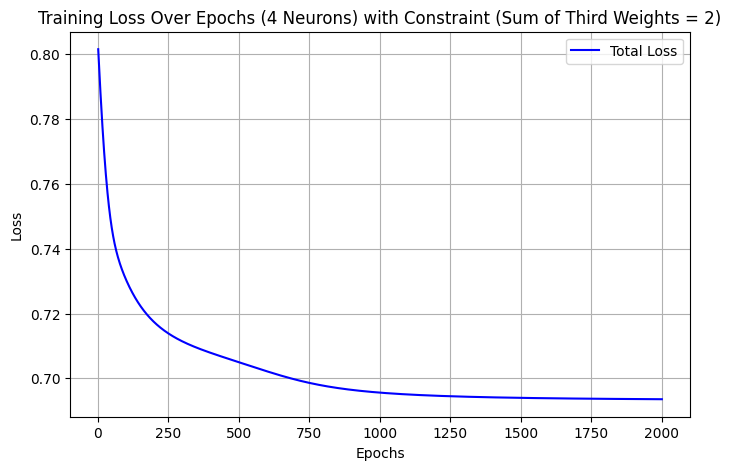

In [7]:
# Re-import necessary libraries after execution state reset
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input), weights[2]  # Return both output and third weight

# Fully Automated Neural Network with Constraint
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        third_weights = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            out, third_weight = neuron(xi)  # Get both the neuron output and third weight
            outputs.append(out)
            third_weights.append(third_weight)

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output, sum(third_weights)

# User-Specified Number of Neurons
num_neurons = 4  # Set number of neurons
input_dim = 4  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(42)
num_samples = 100
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * (1-X_train[:, 1]) > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop with Constraint
num_epochs = 2000
losses = []
lambda_reg = 0.1  # Regularization strength for the constraint

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs, total_third_weight = model(X_train)
    outputs = outputs.squeeze()
    
    # Compute primary loss
    loss = criterion(outputs, y_train)
    
    # Compute weight constraint loss (sum of third weights should be num_neurons - 2)
    constraint_loss = lambda_reg * (total_third_weight - (num_neurons - 2)) ** 2  
    
    # Combined loss
    total_loss = loss + constraint_loss

    # Backpropagation
    total_loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(total_loss.item())

# Print Final Weights After Training
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    print(f"Neuron {i+1} Weights: {weights}, Third Weight: {weights[2]:.4f}")

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Total Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons) with Constraint (Sum of Third Weights = {num_neurons - 2})")
plt.legend()
plt.grid(True)
plt.show()


Weights1: tensor([9.9801e-01, 1.8878e-05, 9.9937e-05], grad_fn=<SigmoidBackward0>).
Weights2: tensor([9.9897e-01, 2.6009e-04, 3.6919e-03], grad_fn=<SigmoidBackward0>).



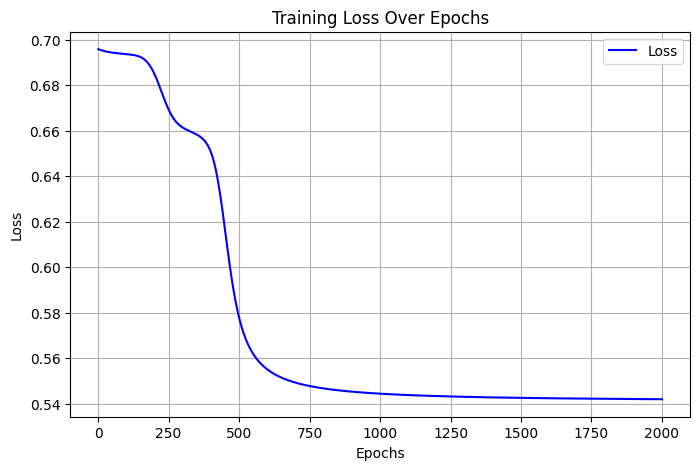

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(-10*torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  # No tensor wrapping

        # Apply log function
        return torch.log(stable_input)

# Full Network with Two Neurons (Different Inputs)
class CustomNeuralNet(nn.Module):
    def __init__(self):
        super(CustomNeuralNet, self).__init__()
        self.neuron1 = CustomNeuron()
        self.neuron2 = CustomNeuron()
    
    def forward(self, x):
        # Split input into two separate inputs (each neuron gets a different feature)
        x1 = x[:, [0]]  # Feature for neuron 1
        x2 = x[:, [1]]  # Feature for neuron 2
        
        # Compute neuron outputs
        out1 = self.neuron1(x1)
        out2 = self.neuron2(x2)
        
        # Sum outputs and apply exponentiation
        output = torch.exp(out1 + out2)
        
        return output

# Generate Synthetic Data (Binary Classification with Two Inputs)
torch.manual_seed(42)
num_samples = 10

X_train = (torch.rand(num_samples, 2) > 0.5).float()  # 100 samples, 2 input features
y_train = (X_train[:, 0] * X_train[:, 1]).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet()
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 2000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

print(f'Weights1: {torch.sigmoid(model.neuron1.raw_weights)}.')
print(f'Weights2: {torch.sigmoid(model.neuron2.raw_weights)}.\n')

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()
